# 🫁 Pneumonia Detection — Hybrid Fusion (DecisionTree + VGG16)

A multimodal pipeline that combines two models:

1. **DecisionTree** trained on the **tabular** data (age, smoking, blood pressure, …)
2. **VGG16** (transfer learning) trained on the **chest X-ray images**
3. **Hybrid fusion** — both models output a *pneumonia probability*, and a small
   **meta-learner** combines the two into a final prediction (late / stacking fusion).

---
### ⚠️ Assumptions (edit the **CONFIG** cell to match your data)
* Your tabular data and your images are treated as **two separate datasets**
  (not linked per patient). Because of that, the fusion step **pairs samples by
  class label** to demonstrate the multimodal architecture. If you ever have a
  patient-ID that links a row to an image, set `FUSION_PAIRING = "by_id"` and
  provide the mapping — a hook is included.
* Images are assumed to live in **class sub-folders** (e.g. `NORMAL/`, `PNEUMONIA/`).
  If they are already split into `train/` and `test/`, set `IMAGE_SPLIT_MODE = "folders"`.
* Nothing needs to be `pip install`-ed — TensorFlow & scikit-learn are pre-installed in Colab.
* **Tip:** Runtime → *Change runtime type* → **GPU** makes VGG16 train much faster.


## 1. Imports & setup

In [8]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image as kimage
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU only — training will be slower)")

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive

In [9]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. CONFIG — ✏️ edit this cell to match your Drive

Run the **folder explorer** in the next cell first to see your real file/folder
names, then correct the paths and column names here.

In [10]:
# =========================  CONFIG — EDIT ME  =========================
# ---- Root folder of your project in Google Drive ----
BASE_DIR = "/content/drive/MyDrive/Pneumonia_automatin"        # <-- confirm this matches your Drive

# ---- Tabular data (pre-filled from your pneumonia_tabular_600.csv) ----
TABULAR_CSV    = os.path.join(BASE_DIR, "pneumonia_tabular_600.csv")  # <-- your CSV
TARGET_COL     = "Pneumonia"       # your label column (values: No / Yes)
DROP_COLS      = ["PatientID"]     # IMPORTANT: PatientID is an identifier, NOT a feature
POSITIVE_LABEL = "Yes"             # "Yes" == pneumonia (mapped to 1)
ID_COL         = "PatientID"       # links a tabular row to its X-ray (for true per-patient fusion)

# ---- Image data ----
IMAGE_SPLIT_MODE = "single_dir"   # "single_dir" = one folder w/ class sub-folders
                                  # "folders"    = separate train/ and test/ folders
IMAGE_DIR       = os.path.join(BASE_DIR, "x-ray image")          # used when "single_dir"
IMAGE_TRAIN_DIR = os.path.join(BASE_DIR, "chest_xray", "train") # used when "folders"
IMAGE_TEST_DIR  = os.path.join(BASE_DIR, "chest_xray", "test")  # used when "folders"

IMG_SIZE   = 224     # VGG16 default input size
BATCH_SIZE = 32
VAL_SPLIT  = 0.2     # held-out fraction when IMAGE_SPLIT_MODE == "single_dir"
IMAGE_ID_REGEX = r"(PX\d+)"  # pulls the PatientID (e.g. PX1367) out of an image filename, for by_id fusion

# ---- Training ----
DT_MAX_DEPTH = 6
VGG_EPOCHS = 20
FINE_TUNE    = True # True -> also unfreeze the top VGG16 block for a few epochs

# ---- Fusion ----
FUSION_PAIRING = "by_label"  # "by_id"    = TRUE per-patient fusion (if X-ray files carry the PatientID)
                             # "by_label" = demo pairing when images are NOT linked to patients
                             # "by_index" = row i of the CSV corresponds to the i-th image
FUSION_META    = "logreg"    # meta-learner: "logreg" or "tree"
# =====================================================================
print("Config loaded. BASE_DIR =", BASE_DIR)

Config loaded. BASE_DIR = /content/drive/MyDrive/Pneumonia_automatin


### 3b. Folder explorer — check your real file names and fix the paths above

In [ ]:
# # Walks BASE_DIR so you can confirm the CSV name and the image folder layout.
# if not os.path.isdir(BASE_DIR):
#     print("❌ BASE_DIR does not exist:", BASE_DIR,
#           "\n   Fix BASE_DIR in the CONFIG cell (check the exact name in Drive).")
# else:
#     for root, dirs, files in os.walk(BASE_DIR):
#         depth = root.replace(BASE_DIR, "").count(os.sep)
#         if depth > 2:
#             continue
#         print("📁", root)
#         for f in sorted(files)[:8]:
#             print("     •", f)
#         if len(files) > 8:
#             print(f"     … (+{len(files) - 8} more files)")

📁 /content/drive/MyDrive/Pneumonia_automatin
     • Pneumonia_Hybrid_Fusion_DecisionTree_VGG16_02.ipynb
     • pneumonia_tabular_600.csv
📁 /content/drive/MyDrive/Pneumonia_automatin/x-ray image
📁 /content/drive/MyDrive/Pneumonia_automatin/x-ray image/PNEUMONIA
     • person1001_bacteria_2932.jpeg
     • person1003_virus_1685.jpeg
     • person1005_bacteria_2936.jpeg
     • person1007_bacteria_2938.jpeg
     • person1007_virus_1690.jpeg
     • person1008_virus_1691.jpeg
     • person1015_virus_1702.jpeg
     • person1017_bacteria_2948.jpeg
     … (+1333 more files)
📁 /content/drive/MyDrive/Pneumonia_automatin/x-ray image/NORMAL
     • IM-0115-0001.jpeg
     • IM-0117-0001.jpeg
     • IM-0119-0001.jpeg
     • IM-0122-0001.jpeg
     • IM-0125-0001.jpeg
     • IM-0127-0001.jpeg
     • IM-0128-0001.jpeg
     • IM-0129-0001.jpeg
     … (+1333 more files)
📁 /content/drive/MyDrive/Pneumonia_automatin/models
     • decisiontree_tabular.joblib
     • feature_names.joblib
     • fusion_meta.jobli

## 4. Tabular branch — DecisionTree

Load the CSV, auto-detect the label column, encode features, train a
`DecisionTreeClassifier`, and keep its predicted probabilities for the fusion step.

In [11]:
assert os.path.exists(TABULAR_CSV), (
    f"CSV not found: {TABULAR_CSV}\nFix TABULAR_CSV in the CONFIG cell.")
df = pd.read_csv(TABULAR_CSV)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (600, 20)
Columns: ['PatientID', 'Age', 'Gender', 'Fever', 'CoughDurationDays', 'ChestPain', 'RespiratoryRate', 'SpO2', 'TemperatureC', 'HeartRate', 'SystolicBP', 'DiastolicBP', 'WBC_kperuL', 'CRP_mgL', 'SmokingStatus', 'ComorbidityCount', 'TachypneaFlag', 'HypoxemiaFlag', 'FeverFlag', 'Pneumonia']


,PatientID,Age,Gender,Fever,CoughDurationDays,ChestPain,RespiratoryRate,SpO2,TemperatureC,HeartRate,SystolicBP,DiastolicBP,WBC_kperuL,CRP_mgL,SmokingStatus,ComorbidityCount,TachypneaFlag,HypoxemiaFlag,FeverFlag,Pneumonia
0,PX1367,29,Female,No,6,No,23,92.7,37.2,92,115,69,8.6,38.3,Former,0,0,0,0,No
1,PX1054,45,Male,No,17,No,17,94.1,37.9,120,111,76,3.0,83.8,Current,1,0,0,0,No
2,PX1547,54,Female,Yes,19,No,22,98.8,38.5,93,117,91,13.5,53.2,Never,0,0,0,1,Yes
3,PX1348,17,Female,No,2,No,24,93.5,37.2,99,103,68,13.9,13.7,Never,1,1,0,0,No
4,PX1400,90,Male,Yes,17,Yes,24,95.2,37.1,113,144,78,11.8,123.4,Former,2,1,0,0,Yes


In [12]:
# ---------- pick the target/label column ----------
def detect_target(frame, target_col):
    if target_col is not None:
        return target_col
    candidates = ["target", "label", "diagnosis", "result", "class",
                  "pneumonia", "outcome", "disease", "y"]
    for c in frame.columns:
        if c.strip().lower() in candidates:
            return c
    return frame.columns[-1]          # fallback: last column

target = detect_target(df, TARGET_COL)
print("Using target column:", repr(target), "(override with TARGET_COL if wrong)")

data = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()
y_raw = data[target]
X_df  = data.drop(columns=[target])

# ---------- encode the label to 0 / 1 ----------
pos_tokens = {"1", "yes", "y", "true", "pneumonia", "positive",
              "abnormal", "sick", "present"}
if not pd.api.types.is_numeric_dtype(y_raw):        # string / category / object labels
    s = y_raw.astype(str).str.strip()
    if POSITIVE_LABEL is not None:
        y = (s == str(POSITIVE_LABEL)).astype(int).values
    elif set(s.str.lower().unique()).issubset({"0", "1"}):
        y = s.astype(int).values
    elif any(t in pos_tokens for t in s.str.lower().unique()):
        y = s.str.lower().isin(pos_tokens).astype(int).values
    else:
        rare = y_raw.value_counts().index[-1]          # assume rarer class = positive
        print(f"Could not auto-map labels; treating {rare!r} as pneumonia (positive).")
        y = (y_raw == rare).astype(int).values
else:
    vals = sorted(pd.unique(y_raw.dropna()))
    if set(vals) == {0, 1}:
        y = y_raw.astype(int).values
    elif POSITIVE_LABEL is not None:
        y = (y_raw == POSITIVE_LABEL).astype(int).values
    else:
        y = (y_raw > np.median(vals)).astype(int).values

print("Class balance  [0=Normal, 1=Pneumonia]:", np.bincount(y))

Using target column: 'Pneumonia' (override with TARGET_COL if wrong)
Class balance  [0=Normal, 1=Pneumonia]: [286 314]


In [13]:
# ---------- encode features (impute + one-hot) ----------
num_cols = X_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_df.columns if c not in num_cols]

for c in num_cols:
    X_df[c] = X_df[c].fillna(X_df[c].median())
for c in cat_cols:
    X_df[c] = X_df[c].astype(str).fillna("missing")

X_enc = pd.get_dummies(X_df, columns=cat_cols, dummy_na=False)
feature_names = X_enc.columns.tolist()          # remembered for single-patient inference
X = X_enc.values.astype(float)
print("Feature matrix:", X.shape, "| numeric:", len(num_cols), "| categorical:", len(cat_cols))

Feature matrix: (600, 23) | numeric: 14 | categorical: 4


In [14]:
# ---------- train + evaluate the DecisionTree ----------
ids_all = (df[ID_COL].astype(str).values if ID_COL in df.columns
           else np.arange(len(y)).astype(str))          # kept aligned for by_id fusion
Xtr, Xte, ytr, yte, dt_id_train, dt_id_test = train_test_split(
    X, y, ids_all, test_size=0.2, random_state=SEED, stratify=y)

dt = DecisionTreeClassifier(max_depth=DT_MAX_DEPTH,
                            class_weight="balanced", random_state=SEED)
dt.fit(Xtr, ytr)

dt_train_prob = dt.predict_proba(Xtr)[:, 1]      # kept for fusion
dt_test_prob  = dt.predict_proba(Xte)[:, 1]      # kept for fusion
dt_pred = (dt_test_prob >= 0.5).astype(int)

print("================  DecisionTree (tabular)  ================")
print("Accuracy:", round(accuracy_score(yte, dt_pred), 4))
try:
    print("ROC-AUC :", round(roc_auc_score(yte, dt_test_prob), 4))
except Exception:
    pass
print(classification_report(yte, dt_pred, target_names=["Normal", "Pneumonia"]))

================  DecisionTree (tabular)  ================
Accuracy: 0.6167
ROC-AUC : 0.5728
              precision    recall  f1-score   support

      Normal       0.61      0.54      0.57        57
   Pneumonia       0.62      0.68      0.65        63

    accuracy                           0.62       120
   macro avg       0.62      0.61      0.61       120
weighted avg       0.62      0.62      0.61       120



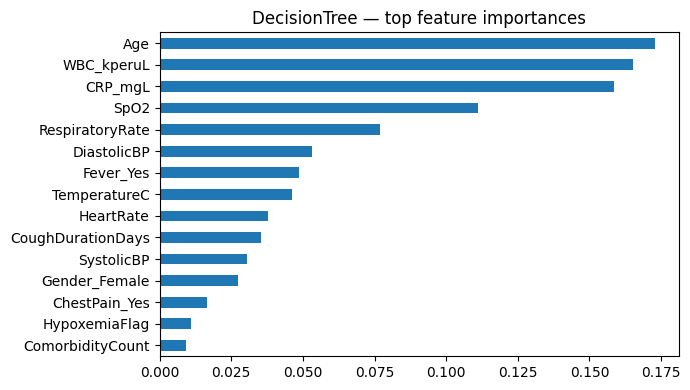

In [15]:
# ---------- feature importances (top 15) ----------
imp = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 4))
imp[::-1].plot(kind="barh")
plt.title("DecisionTree — top feature importances")
plt.tight_layout(); plt.show()

## 5. Image branch — VGG16 (transfer learning)

Build image data generators, then a VGG16 base (ImageNet weights, frozen) with a
small classification head on top.

> **Note on labels:** Keras assigns class indices alphabetically, so with folders
> `NORMAL/` and `PNEUMONIA/` you get `NORMAL=0`, `PNEUMONIA=1` — matching the tabular side.

In [16]:
# Augmentation for training; plain preprocessing for evaluation.
_split = VAL_SPLIT if IMAGE_SPLIT_MODE == "single_dir" else 0.0
train_aug = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10, zoom_range=0.10,
    width_shift_range=0.05, height_shift_range=0.05,
    validation_split=_split)
plain_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input, validation_split=_split)

common = dict(target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
              class_mode="binary", seed=SEED)

if IMAGE_SPLIT_MODE == "single_dir":
    assert os.path.isdir(IMAGE_DIR), f"IMAGE_DIR not found: {IMAGE_DIR} — fix CONFIG."
    train_flow      = train_aug.flow_from_directory(IMAGE_DIR, subset="training",   shuffle=True,  **common)
    test_flow       = plain_gen.flow_from_directory(IMAGE_DIR, subset="validation", shuffle=False, **common)
    train_eval_flow = plain_gen.flow_from_directory(IMAGE_DIR, subset="training",   shuffle=False, **common)
elif IMAGE_SPLIT_MODE == "folders":
    assert os.path.isdir(IMAGE_TRAIN_DIR), f"IMAGE_TRAIN_DIR not found: {IMAGE_TRAIN_DIR} — fix CONFIG."
    assert os.path.isdir(IMAGE_TEST_DIR),  f"IMAGE_TEST_DIR not found: {IMAGE_TEST_DIR} — fix CONFIG."
    train_flow      = train_aug.flow_from_directory(IMAGE_TRAIN_DIR, shuffle=True,  **common)
    test_flow       = plain_gen.flow_from_directory(IMAGE_TEST_DIR,  shuffle=False, **common)
    train_eval_flow = plain_gen.flow_from_directory(IMAGE_TRAIN_DIR, shuffle=False, **common)

print("Class indices:", train_flow.class_indices)
print("Train images:", train_flow.samples, "| Test images:", test_flow.samples)

Found 2146 images belonging to 2 classes.
Found 536 images belonging to 2 classes.
Found 2146 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Train images: 2146 | Test images: 536


In [17]:
# ---------- build the VGG16 transfer-learning model ----------
base = VGG16(weights="imagenet", include_top=False,
             input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False                      # freeze the convolutional base

vgg = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
vgg.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
            loss="binary_crossentropy", metrics=["accuracy"])
vgg.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,747,585 (56.26 MB)

 Trainable params: 32,897 (128.50 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# ---------- train ----------
es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = vgg.fit(train_flow, validation_data=test_flow,
                  epochs=VGG_EPOCHS, callbacks=[es])
#callbacks=[es]callback, which halted training
#when validation loss stopped improving

In [ ]:
# ---------- (optional) fine-tune the top conv block ----------
if FINE_TUNE:
    base.trainable = True
    for layer in base.layers[:-4]:          # keep all but the last block frozen
        layer.trainable = False
    vgg.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                loss="binary_crossentropy", metrics=["accuracy"])
    history_ft = vgg.fit(train_flow, validation_data=test_flow,
                         epochs=4, callbacks=[es])

Epoch 1/4
68/68 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.8807 - loss: 0.2962 - val_accuracy: 0.9422 - val_loss: 0.1680
Epoch 2/4
68/68 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.9334 - loss: 0.1881 - val_accuracy: 0.9571 - val_loss: 0.1203
Epoch 3/4
68/68 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.9413 - loss: 0.1636 - val_accuracy: 0.9104 - val_loss: 0.2301
Epoch 4/4
68/68 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.9534 - loss: 0.1324 - val_accuracy: 0.9496 - val_loss: 0.1229


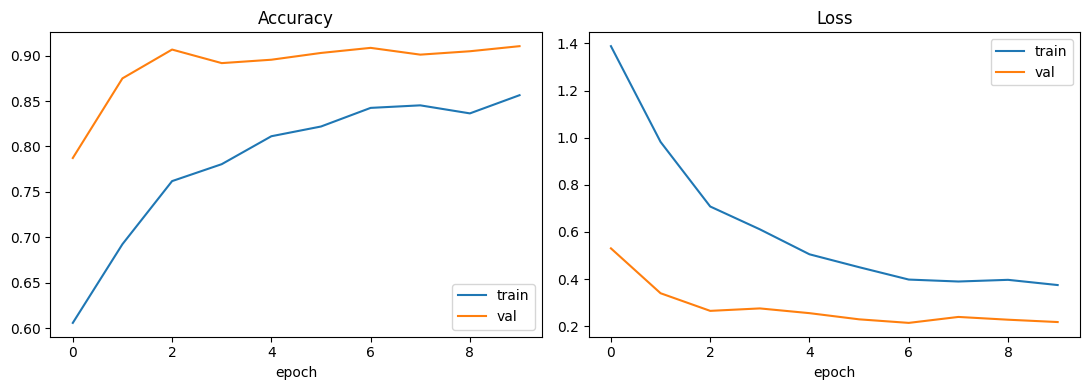

In [ ]:
# ---------- training curves ----------
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
# ---------- evaluate VGG16 + collect probabilities for fusion ----------
vgg_test_prob  = vgg.predict(test_flow).ravel()
y_img_test     = test_flow.classes                # aligned because shuffle=False
vgg_train_prob = vgg.predict(train_eval_flow).ravel()
y_img_train    = train_eval_flow.classes
vgg_pred = (vgg_test_prob >= 0.5).astype(int)

class_labels = list(train_flow.class_indices.keys())
print("================  VGG16 (x-ray)  ================")
print("Accuracy:", round(accuracy_score(y_img_test, vgg_pred), 4))
try:
    print("ROC-AUC :", round(roc_auc_score(y_img_test, vgg_test_prob), 4))
except Exception:
    pass
print(classification_report(y_img_test, vgg_pred, target_names=class_labels))

17/17 ━━━━━━━━━━━━━━━━━━━━ 13s 589ms/step
68/68 ━━━━━━━━━━━━━━━━━━━━ 40s 577ms/step
================  VGG16 (x-ray)  ================
Accuracy: 0.9571
ROC-AUC : 0.993
              precision    recall  f1-score   support

      NORMAL       0.93      0.99      0.96       268
   PNEUMONIA       0.99      0.93      0.96       268

    accuracy                           0.96       536
   macro avg       0.96      0.96      0.96       536
weighted avg       0.96      0.96      0.96       536



## 6. Hybrid fusion (late / stacking fusion)

Each model produces a pneumonia probability. We stack those two probabilities
`[vgg_prob, dt_prob]` and train a **meta-learner** to make the final call.

Because your tabular and image datasets are **not linked per patient**, we build
the paired fusion set by **matching samples that share the same class label**
(`FUSION_PAIRING="by_label"`). This demonstrates the architecture and lets fusion
correct cases where one modality is wrong.

> **For a clinically valid multimodal model** you need *real per-patient pairs*
> (the same patient's X-ray **and** clinical record). If you have a patient-ID that
> links them, set `FUSION_PAIRING="by_id"` and fill in `img_ids` / `tab_ids` below.

In [ ]:
def make_pairs(img_prob, img_y, tab_prob, tab_y, mode="by_label",
               img_ids=None, tab_ids=None, seed=SEED):
    """Return X = [[vgg_prob, dt_prob], ...] and matching labels."""
    rng = np.random.default_rng(seed)

    if mode == "by_index":                     # row i of tabular == i-th image
        n = min(len(img_prob), len(tab_prob))
        return np.column_stack([img_prob[:n], tab_prob[:n]]), np.asarray(img_y[:n])

    if mode == "by_id":                        # true pairing via shared patient id
        assert img_ids is not None and tab_ids is not None, "Provide img_ids and tab_ids."
        tab_lookup = {pid: k for k, pid in enumerate(tab_ids)}
        feats, labels = [], []
        for p_img, yi, pid in zip(img_prob, img_y, img_ids):
            if pid in tab_lookup:
                feats.append([p_img, tab_prob[tab_lookup[pid]]]); labels.append(yi)
        return np.array(feats), np.array(labels)

    # default: by_label — pair each image with a same-class tabular sample
    feats, labels = [], []
    tab_by_class = {c: np.where(np.asarray(tab_y) == c)[0] for c in np.unique(tab_y)}
    for p_img, c in zip(img_prob, img_y):
        pool = tab_by_class.get(c)
        if pool is None or len(pool) == 0:
            continue
        feats.append([p_img, tab_prob[rng.choice(pool)]]); labels.append(c)
    return np.array(feats), np.array(labels)

# For by_id fusion: pull the PatientID out of each image filename and pair it with
# that patient's tabular prediction. (This branch runs only when FUSION_PAIRING == "by_id".)
import re
def ids_from_filenames(flow):
    out = []
    for fn in flow.filenames:                      # e.g. "PNEUMONIA/PX1367.png"
        m = re.search(IMAGE_ID_REGEX, os.path.basename(fn))
        out.append(m.group(1) if m else None)
    return np.array(out)

if FUSION_PAIRING == "by_id":
    img_ids_train, img_ids_test = ids_from_filenames(train_eval_flow), ids_from_filenames(test_flow)
    tab_ids_train, tab_ids_test = dt_id_train, dt_id_test
    matched = len(set(img_ids_test) & set(tab_ids_test))
    print(f"by_id: matched {matched} test patients between images and tabular "
          f"(0 -> check IMAGE_ID_REGEX / how your images are named).")
else:
    img_ids_train = img_ids_test = tab_ids_train = tab_ids_test = None

F_tr, L_tr = make_pairs(vgg_train_prob, y_img_train, dt_train_prob, ytr,
                        FUSION_PAIRING, img_ids_train, tab_ids_train)
F_te, L_te = make_pairs(vgg_test_prob,  y_img_test,  dt_test_prob,  yte,
                        FUSION_PAIRING, img_ids_test,  tab_ids_test)
print("Fusion feature set -> train:", F_tr.shape, "| test:", F_te.shape)

Fusion feature set -> train: (2146, 2) | test: (536, 2)


In [ ]:
# ---------- train the meta-learner ----------
meta = (DecisionTreeClassifier(max_depth=3, random_state=SEED)
        if FUSION_META == "tree" else LogisticRegression())
meta.fit(F_tr, L_tr)

fusion_prob = meta.predict_proba(F_te)[:, 1]
fusion_pred = (fusion_prob >= 0.5).astype(int)

avg_prob = F_te.mean(axis=1)                 # simple-average baseline
avg_pred = (avg_prob >= 0.5).astype(int)

print("================  Hybrid Fusion  ================")
print(f"Meta-learner ({FUSION_META}) accuracy:", round(accuracy_score(L_te, fusion_pred), 4))
try:
    print("Meta-learner ROC-AUC :", round(roc_auc_score(L_te, fusion_prob), 4))
except Exception:
    pass
print("Simple-average accuracy:", round(accuracy_score(L_te, avg_pred), 4))
print(classification_report(L_te, fusion_pred, target_names=["Normal", "Pneumonia"]))

================  Hybrid Fusion  ================
Meta-learner (logreg) accuracy: 0.9608
Meta-learner ROC-AUC : 0.9783
Simple-average accuracy: 0.8321
              precision    recall  f1-score   support

      Normal       0.95      0.97      0.96       268
   Pneumonia       0.97      0.95      0.96       268

    accuracy                           0.96       536
   macro avg       0.96      0.96      0.96       536
weighted avg       0.96      0.96      0.96       536



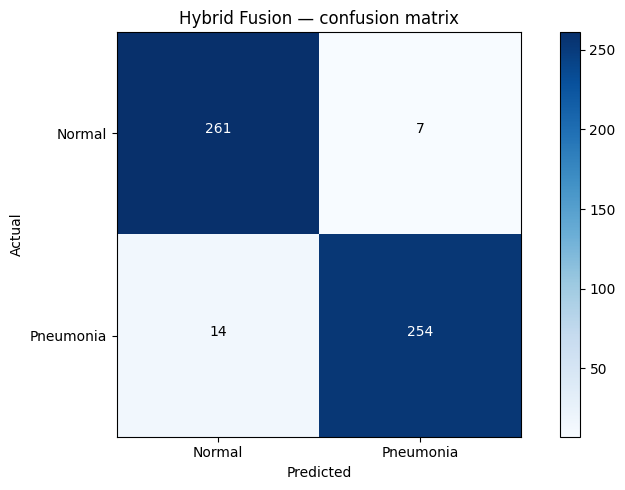

In [ ]:
# ---------- confusion matrix for the fusion model ----------
cm = confusion_matrix(L_te, fusion_pred)
plt.figure(figsize=(8,
                    5))
plt.imshow(cm, cmap="Blues")
plt.title("Hybrid Fusion — confusion matrix")
plt.colorbar()
plt.xticks([0, 1], ["Normal", "Pneumonia"]); plt.yticks([0, 1], ["Normal", "Pneumonia"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

## 7. Compare the three models

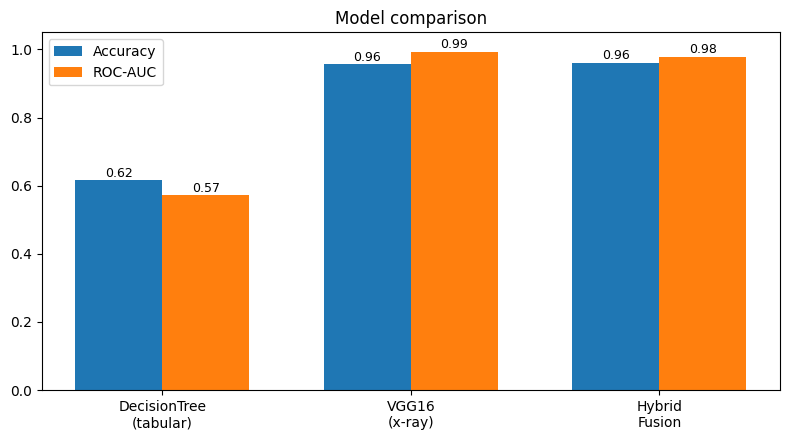

,Accuracy,ROC-AUC
DecisionTree\n(tabular),0.6167,0.5728
VGG16\n(x-ray),0.9571,0.9930
Hybrid\nFusion,0.9608,0.9783


In [ ]:
def safe_auc(y_true, prob):
    try:
        return roc_auc_score(y_true, prob)
    except Exception:
        return float("nan")

results = {
    "DecisionTree\n(tabular)": (accuracy_score(yte, dt_pred),            safe_auc(yte, dt_test_prob)),
    "VGG16\n(x-ray)":          (accuracy_score(y_img_test, vgg_pred),    safe_auc(y_img_test, vgg_test_prob)),
    "Hybrid\nFusion":          (accuracy_score(L_te, fusion_pred),       safe_auc(L_te, fusion_prob)),
}
names = list(results)
accs  = [results[n][0] for n in names]
aucs  = [results[n][1] for n in names]

x = np.arange(len(names)); w = 0.35
plt.figure(figsize=(8, 4.5))
plt.bar(x - w/2, accs, w, label="Accuracy")
plt.bar(x + w/2, aucs, w, label="ROC-AUC")
plt.xticks(x, names); plt.ylim(0, 1.05); plt.legend(); plt.title("Model comparison")
for i, (a, b) in enumerate(zip(accs, aucs)):
    plt.text(i - w/2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    if not np.isnan(b):
        plt.text(i + w/2, b + 0.01, f"{b:.2f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

pd.DataFrame(results, index=["Accuracy", "ROC-AUC"]).T.round(4)

## Confusion Matrix for DecisionTree Model

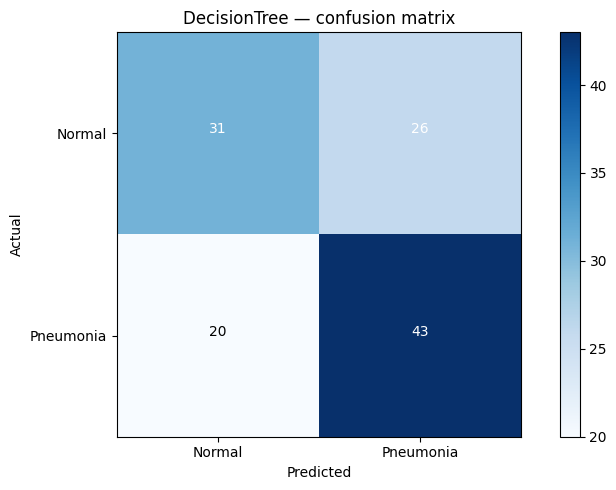

In [ ]:
cm_dt = confusion_matrix(yte, dt_pred)
plt.figure(figsize=(8, 5))
plt.imshow(cm_dt, cmap="Blues")
plt.title("DecisionTree — confusion matrix")
plt.colorbar()
plt.xticks([0, 1], ["Normal", "Pneumonia"]);
plt.yticks([0, 1], ["Normal", "Pneumonia"])
plt.xlabel("Predicted");
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_dt[i, j], ha="center",
                 color="white" if cm_dt[i, j] > cm_dt.max() / 2 else "black")
plt.tight_layout();
plt.show()

## ROC Curve for DecisionTree Model

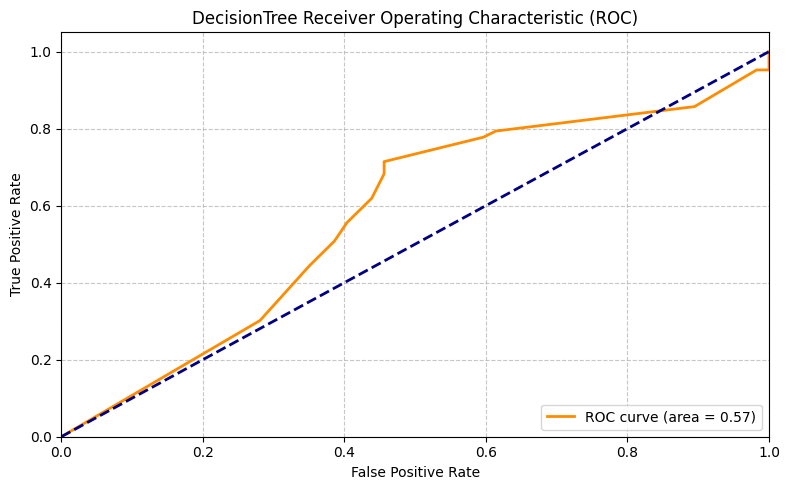

In [ ]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve for DecisionTree
fpr_dt, tpr_dt, _ = roc_curve(yte, dt_test_prob)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(8, 5))
plt.plot(fpr_dt, tpr_dt, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_dt:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('DecisionTree Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Confusion Matrix for VGG16 Model

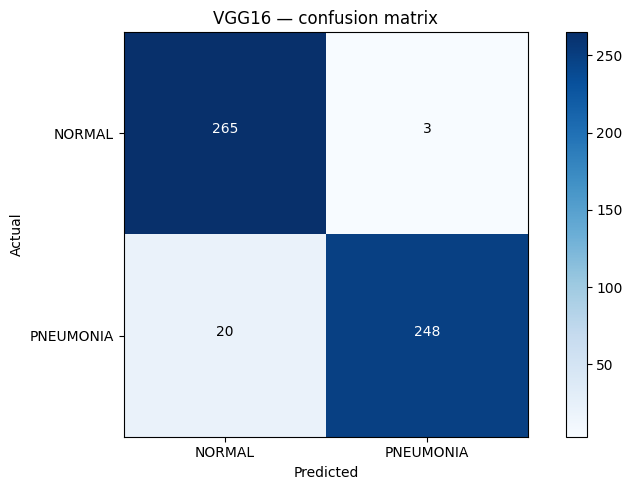

In [ ]:
cm_vgg16 = confusion_matrix(y_img_test, vgg_pred)
plt.figure(figsize=(8, 5))
plt.imshow(cm_vgg16, cmap="Blues")
plt.title("VGG16 — confusion matrix")
plt.colorbar()
plt.xticks([0, 1], class_labels);
plt.yticks([0, 1], class_labels)
plt.xlabel("Predicted");
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_vgg16[i, j], ha="center",
                 color="white" if cm_vgg16[i, j] > cm_vgg16.max() / 2 else "black")
plt.tight_layout();
plt.show()

## ROC Curve for VGG16 Model

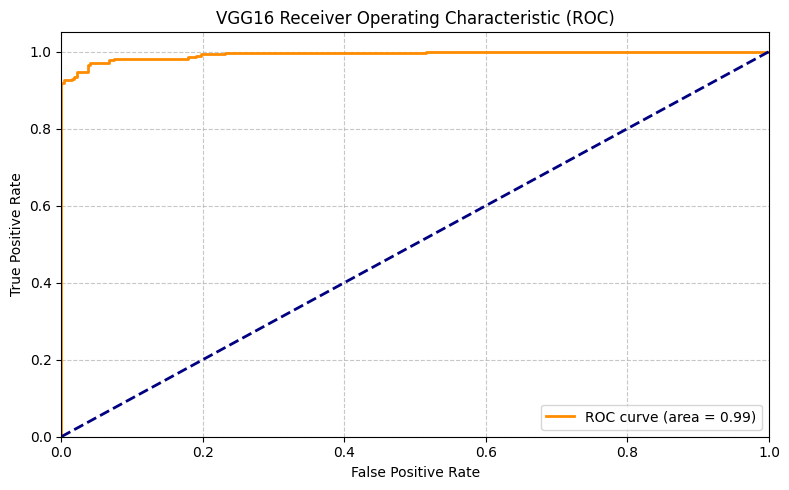

In [ ]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve for VGG16
fpr_vgg16, tpr_vgg16, _ = roc_curve(y_img_test, vgg_test_prob)
roc_auc_vgg16 = auc(fpr_vgg16, tpr_vgg16)

plt.figure(figsize=(8, 5))
plt.plot(fpr_vgg16, tpr_vgg16, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_vgg16:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('VGG16 Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 11. Additional image backbones — ResNet50 & DenseNet121 (+ hybrid fusion)

We now repeat the exact same recipe used for VGG16 with two more transfer-learning
backbones — **ResNet50** and **DenseNet121** — and fuse each one with the same
**DecisionTree** tabular model through a **meta-learner** (stacking fusion).

Everything is kept identical to the VGG16 pipeline so the comparison is fair:

* same frozen ImageNet base + `GlobalAveragePooling2D → Dropout → Dense(64) → Dense(1)` head,
* same optimizer / epochs / EarlyStopping and the same optional top-block fine-tune,
* same `make_pairs` pairing and the same `FUSION_META` meta-learner,
* evaluated on the **same** held-out image test set as VGG16.

> ⚠️ **Important:** each backbone needs its *own* `preprocess_input`. ResNet50 and
> DenseNet121 normalise pixels differently from VGG16, so we rebuild the data
> generators per backbone with the matching preprocessing function.


In [ ]:
# ============================================================================
#  Reusable helpers: build data flows (with a given preprocessing fn),
#  build+train a transfer-learning backbone, and fuse it with the DecisionTree.
#  These mirror the VGG16 cells above so all three models are strictly comparable.
# ============================================================================
from tensorflow.keras.applications import ResNet50, DenseNet121
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from sklearn.metrics import roc_curve, auc

def safe_auc(y_true, prob):
    try:
        return roc_auc_score(y_true, prob)
    except Exception:
        return float("nan")

def make_flows(preprocess_fn):
    """Rebuild train / test / train-eval generators for a given backbone's preprocessing."""
    _split = VAL_SPLIT if IMAGE_SPLIT_MODE == "single_dir" else 0.0
    train_aug = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        rotation_range=10, zoom_range=0.10,
        width_shift_range=0.05, height_shift_range=0.05,
        validation_split=_split)
    plain_gen = ImageDataGenerator(
        preprocessing_function=preprocess_fn, validation_split=_split)
    common = dict(target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
                  class_mode="binary", seed=SEED)
    if IMAGE_SPLIT_MODE == "single_dir":
        tr  = train_aug.flow_from_directory(IMAGE_DIR, subset="training",   shuffle=True,  **common)
        te  = plain_gen.flow_from_directory(IMAGE_DIR, subset="validation", shuffle=False, **common)
        tre = plain_gen.flow_from_directory(IMAGE_DIR, subset="training",   shuffle=False, **common)
    else:
        tr  = train_aug.flow_from_directory(IMAGE_TRAIN_DIR, shuffle=True,  **common)
        te  = plain_gen.flow_from_directory(IMAGE_TEST_DIR,  shuffle=False, **common)
        tre = plain_gen.flow_from_directory(IMAGE_TRAIN_DIR, shuffle=False, **common)
    return tr, te, tre

def build_and_train_backbone(base_ctor, preprocess_fn, name):
    """Build a frozen-base transfer model, train (+ optional fine-tune), and
    return the model, history, and probabilities/labels for train & test."""
    print(f"\n=========== Building & training {name} ===========")
    tr, te, tre = make_flows(preprocess_fn)

    base = base_ctor(weights="imagenet", include_top=False,
                     input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                      # freeze the convolutional base

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss="binary_crossentropy", metrics=["accuracy"])

    es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    history = model.fit(tr, validation_data=te, epochs=VGG_EPOCHS, callbacks=[es])

    # ---- optional fine-tune of the top conv block (same as VGG16) ----
    if FINE_TUNE:
        base.trainable = True
        for layer in base.layers[:-4]:          # keep all but the last few layers frozen
            layer.trainable = False
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                      loss="binary_crossentropy", metrics=["accuracy"])
        model.fit(tr, validation_data=te, epochs=4, callbacks=[es])

    # ---- collect probabilities for the fusion step ----
    test_prob  = model.predict(te).ravel()
    train_prob = model.predict(tre).ravel()
    return dict(name=name, model=model, history=history,
                test_prob=test_prob, train_prob=train_prob,
                y_test=te.classes, y_train=tre.classes,
                test_flow=te, train_eval_flow=tre,
                class_labels=list(tr.class_indices.keys()))

def evaluate_backbone(res):
    """Print the standalone image-model report and return (pred, acc, auc)."""
    pred = (res["test_prob"] >= 0.5).astype(int)
    acc  = accuracy_score(res["y_test"], pred)
    a    = safe_auc(res["y_test"], res["test_prob"])
    print(f"================  {res['name']} (x-ray)  ================")
    print("Accuracy:", round(acc, 4), "| ROC-AUC:", round(a, 4))
    print(classification_report(res["y_test"], pred, target_names=res["class_labels"]))
    return pred, acc, a

def fuse_backbone(res):
    """Fuse an image backbone with the DecisionTree via the same meta-learner."""
    # by_id pairing needs patient ids parsed from the image filenames
    if FUSION_PAIRING == "by_id":
        img_ids_tr = ids_from_filenames(res["train_eval_flow"])
        img_ids_te = ids_from_filenames(res["test_flow"])
        tab_ids_tr, tab_ids_te = dt_id_train, dt_id_test
    else:
        img_ids_tr = img_ids_te = tab_ids_tr = tab_ids_te = None

    F_tr, L_tr = make_pairs(res["train_prob"], res["y_train"], dt_train_prob, ytr,
                            FUSION_PAIRING, img_ids_tr, tab_ids_tr)
    F_te, L_te = make_pairs(res["test_prob"],  res["y_test"],  dt_test_prob,  yte,
                            FUSION_PAIRING, img_ids_te, tab_ids_te)

    m = (DecisionTreeClassifier(max_depth=3, random_state=SEED)
         if FUSION_META == "tree" else LogisticRegression())
    m.fit(F_tr, L_tr)

    fusion_prob = m.predict_proba(F_te)[:, 1]
    fusion_pred = (fusion_prob >= 0.5).astype(int)
    acc = accuracy_score(L_te, fusion_pred)
    a   = safe_auc(L_te, fusion_prob)
    print(f"================  {res['name']} + Hybrid Fusion ({FUSION_META})  ================")
    print("Fusion accuracy:", round(acc, 4), "| Fusion ROC-AUC:", round(a, 4))
    print(classification_report(L_te, fusion_pred, target_names=["Normal", "Pneumonia"]))
    return dict(meta=m, fusion_prob=fusion_prob, fusion_pred=fusion_pred,
                L_te=L_te, acc=acc, auc=a)

print("Helper functions ready: make_flows, build_and_train_backbone, evaluate_backbone, fuse_backbone")


In [ ]:
# ---------- ResNet50: build, train, evaluate (standalone image model) ----------
resnet_res = build_and_train_backbone(ResNet50, resnet_preprocess, "ResNet50")
resnet_pred, resnet_acc, resnet_auc = evaluate_backbone(resnet_res)


In [ ]:
# ---------- ResNet50 + DecisionTree hybrid fusion ----------
resnet_fus = fuse_backbone(resnet_res)


In [ ]:
# ---------- DenseNet121: build, train, evaluate (standalone image model) ----------
dense_res = build_and_train_backbone(DenseNet121, densenet_preprocess, "DenseNet121")
dense_pred, dense_acc, dense_auc = evaluate_backbone(dense_res)


In [ ]:
# ---------- DenseNet121 + DecisionTree hybrid fusion ----------
dense_fus = fuse_backbone(dense_res)


## 12. Compare VGG16 vs ResNet50 vs DenseNet121

We compare all three image backbones **on their own** and **after hybrid fusion**
with the DecisionTree, using Accuracy and ROC-AUC, plus overlaid ROC curves and a
grid of confusion matrices. (The VGG16 numbers reuse `vgg_test_prob` / `fusion_prob`
computed earlier in the notebook.)


In [ ]:
# ---------- assemble a tidy results table for all six configurations ----------
def _metrics(y_true, prob):
    pred = (np.asarray(prob) >= 0.5).astype(int)
    return accuracy_score(y_true, pred), safe_auc(y_true, prob)

backbone_scores = {
    "VGG16":       _metrics(y_img_test,          vgg_test_prob),
    "ResNet50":    _metrics(resnet_res["y_test"], resnet_res["test_prob"]),
    "DenseNet121": _metrics(dense_res["y_test"],  dense_res["test_prob"]),
}
fusion_scores = {
    "VGG16":       (accuracy_score(L_te, fusion_pred), safe_auc(L_te, fusion_prob)),
    "ResNet50":    (resnet_fus["acc"], resnet_fus["auc"]),
    "DenseNet121": (dense_fus["acc"],  dense_fus["auc"]),
}

summary = pd.DataFrame({
    "Backbone Accuracy": {k: round(v[0], 4) for k, v in backbone_scores.items()},
    "Backbone ROC-AUC":  {k: round(v[1], 4) for k, v in backbone_scores.items()},
    "Fusion Accuracy":   {k: round(v[0], 4) for k, v in fusion_scores.items()},
    "Fusion ROC-AUC":    {k: round(v[1], 4) for k, v in fusion_scores.items()},
})
print("================  Model comparison summary  ================")
print(summary)
summary


In [ ]:
# ---------- grouped bar charts: backbone vs fusion, for Accuracy and ROC-AUC ----------
archs = ["VGG16", "ResNet50", "DenseNet121"]
x = np.arange(len(archs)); w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric_idx, title in [(axes[0], 0, "Accuracy"), (axes[1], 1, "ROC-AUC")]:
    back = [backbone_scores[a][metric_idx] for a in archs]
    fuse = [fusion_scores[a][metric_idx]   for a in archs]
    b1 = ax.bar(x - w/2, back, w, label="Backbone only", color="#4C78A8")
    b2 = ax.bar(x + w/2, fuse, w, label="+ Hybrid Fusion", color="#F58518")
    ax.set_xticks(x); ax.set_xticklabels(archs)
    ax.set_ylim(0, 1.08); ax.set_title(f"Image model comparison — {title}")
    ax.legend(loc="lower right")
    for bars in (b1, b2):
        for r in bars:
            h = r.get_height()
            if not np.isnan(h):
                ax.text(r.get_x() + r.get_width()/2, h + 0.01, f"{h:.3f}",
                        ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()


In [ ]:
# ---------- overlaid ROC curves for all three backbones and their fusions ----------
roc_sources = {
    "VGG16 (backbone)":        (y_img_test,          vgg_test_prob,        "-",  "#4C78A8"),
    "ResNet50 (backbone)":     (resnet_res["y_test"], resnet_res["test_prob"], "-",  "#54A24B"),
    "DenseNet121 (backbone)":  (dense_res["y_test"],  dense_res["test_prob"],  "-",  "#B279A2"),
    "VGG16 + Fusion":          (L_te,                fusion_prob,          "--", "#4C78A8"),
    "ResNet50 + Fusion":       (resnet_fus["L_te"],  resnet_fus["fusion_prob"], "--", "#54A24B"),
    "DenseNet121 + Fusion":    (dense_fus["L_te"],   dense_fus["fusion_prob"],  "--", "#B279A2"),
}

plt.figure(figsize=(8, 7))
for label, (yt, pr, ls, color) in roc_sources.items():
    fpr, tpr, _ = roc_curve(yt, pr)
    plt.plot(fpr, tpr, ls, color=color, lw=2, label=f"{label} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle=":")
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC — VGG16 vs ResNet50 vs DenseNet121 (backbone vs fusion)")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout(); plt.show()


In [ ]:
# ---------- confusion matrices: backbone (top row) vs fusion (bottom row) ----------
cm_specs = [
    ("VGG16",       y_img_test,          (vgg_test_prob        >= 0.5).astype(int)),
    ("ResNet50",    resnet_res["y_test"], resnet_pred),
    ("DenseNet121", dense_res["y_test"],  dense_pred),
    ("VGG16 + Fusion",       L_te,               fusion_pred),
    ("ResNet50 + Fusion",    resnet_fus["L_te"], resnet_fus["fusion_pred"]),
    ("DenseNet121 + Fusion", dense_fus["L_te"],  dense_fus["fusion_pred"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (title, y_true, pred) in zip(axes.ravel(), cm_specs):
    cm = confusion_matrix(y_true, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(title, fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Pneumonia"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Pneumonia"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
plt.suptitle("Confusion matrices — backbone (top) vs hybrid fusion (bottom)", fontsize=13)
plt.tight_layout(); plt.show()


## 8. Predict for a single patient (X-ray + clinical row)

Combines both modalities for one patient. Give a path to an X-ray and a dict of
tabular features (using the **same column names as your CSV**).

In [ ]:
def predict_patient(image_path, tabular_row):
    """Fused pneumonia prediction for one patient.
    image_path  : path to a chest x-ray image
    tabular_row : dict like {"age": 60, "smoking": "yes", "blood_pressure": 140}
                  keys should match the original CSV feature columns.
    """
    # --- image branch ---
    img = kimage.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    arr = preprocess_input(kimage.img_to_array(img)[None, ...])
    p_img = float(vgg.predict(arr, verbose=0).ravel()[0])

    # --- tabular branch (encode the row the same way as training) ---
    row = pd.get_dummies(pd.DataFrame([tabular_row]))
    row = row.reindex(columns=feature_names, fill_value=0)
    p_tab = float(dt.predict_proba(row.values.astype(float))[:, 1][0])

    # --- fuse ---
    p_fused = float(meta.predict_proba([[p_img, p_tab]])[:, 1][0])
    verdict = "PNEUMONIA" if p_fused >= 0.5 else "NORMAL"
    print(f"X-ray prob = {p_img:.3f} | Tabular prob = {p_tab:.3f} "
          f"| Fused = {p_fused:.3f}  ->  {verdict}")
    return p_fused

# Example — edit the path and values, then uncomment:
# predict_patient("/content/drive/MyDrive/Pneumonia_automatin02/chest_xray/PNEUMONIA/xxxx.jpeg",
#                 {"age": 62, "smoking": "yes", "blood_pressure": 145})

## 9. (Optional) Save the trained models to Drive

In [ ]:
SAVE = True   # set True to save
if SAVE:
    import joblib
    out = os.path.join(BASE_DIR, "models"); os.makedirs(out, exist_ok=True)
    vgg.save(os.path.join(out, "vgg16_xray.keras"))
    joblib.dump(dt,   os.path.join(out, "decisiontree_tabular.joblib"))
    joblib.dump(meta, os.path.join(out, "fusion_meta.joblib"))
    joblib.dump(feature_names, os.path.join(out, "feature_names.joblib"))
    print("Saved to", out)

Saved to /content/drive/MyDrive/Pneumonia_automatin02/models


---
### Notes & how to adapt
* **Wrong label column?** Set `TARGET_COL` in CONFIG to the exact column name.
* **Labels not mapping to Normal/Pneumonia correctly?** Set `POSITIVE_LABEL` to the
  value that means pneumonia (e.g. `"Pneumonia"` or `1`).
* **Images not found?** Run the folder explorer (cell 3b) and fix `IMAGE_DIR`
  (or switch to `IMAGE_SPLIT_MODE="folders"` with `IMAGE_TRAIN_DIR`/`IMAGE_TEST_DIR`).
* **Fusion caveat:** with `by_label` pairing the reported fusion score is a
  *demonstration* of the architecture, not a per-patient clinical result. Use
  `by_id` pairing once you have paired data for a valid multimodal evaluation.
* **Faster training:** enable a GPU runtime, lower `IMG_SIZE` to 150, or reduce `VGG_EPOCHS`.


## 10. Interactive prediction — enter a patient & X-ray

Run every cell above first (so `vgg`, `dt`, `meta`, `feature_names` exist), then run this
cell. A form appears: fill in the patient's data, give the **Image Path** to a chest X-ray
(e.g. `PNEUMONIA/person1001_bacteria_2932.jpeg`), and click **Run Prediction**.

> The three engineered flags (Tachypnea / Hypoxemia / Fever) are computed automatically from
> Respiratory Rate, SpO2 and Temperature — the same rules used to build your dataset.

In [ ]:
# ============================================================================
#  10. INTERACTIVE PREDICTION  —  enter a patient's data + chest X-ray path,
#      then click "Run Prediction" to get the Hybrid-Fusion result.
#      (Run this AFTER the whole notebook has trained: it uses vgg, dt, meta,
#       feature_names, IMG_SIZE, IMAGE_DIR, BASE_DIR.)
# ============================================================================
import ipywidgets as widgets
from IPython.display import display, HTML, Image, clear_output
import glob

# ---------- inference helpers (verified to match the training encoding) ----------
def derive_flags(rr, spo2, temp):
    """Recreate the dataset's engineered flags from the raw vitals."""
    return {"TachypneaFlag": int(rr >= 24),       # RR > 23
            "HypoxemiaFlag": int(spo2 < 92),      # SpO2 <= 91.9
            "FeverFlag":     int(temp >= 38.0)}   # Temp > 37.9

def build_feature_row(inp):
    row = {k: inp[k] for k in
           ["Age", "Gender", "Fever", "CoughDurationDays", "ChestPain", "RespiratoryRate",
            "SpO2", "TemperatureC", "HeartRate", "SystolicBP", "DiastolicBP", "WBC_kperuL",
            "CRP_mgL", "SmokingStatus", "ComorbidityCount"]}
    row.update(derive_flags(inp["RespiratoryRate"], inp["SpO2"], inp["TemperatureC"]))
    return row

def resolve_image_path(p):
    """Accept an absolute path, a path relative to IMAGE_DIR/BASE_DIR, or just a filename."""
    p = (p or "").strip()
    if not p:
        return None
    for c in [p, os.path.join(IMAGE_DIR, p), os.path.join(BASE_DIR, p)]:
        if os.path.exists(c):
            return c
    hits = glob.glob(os.path.join(BASE_DIR, "**", os.path.basename(p)), recursive=True)
    return hits[0] if hits else None

def predict_from_inputs(inp, image_path):
    # --- clinical / tabular branch (DecisionTree) ---
    enc = pd.get_dummies(pd.DataFrame([build_feature_row(inp)]))
    enc = enc.reindex(columns=feature_names, fill_value=0)
    p_tab = float(dt.predict_proba(enc.values.astype(float))[:, 1][0])

    # --- image branch (VGG16) ---
    path = resolve_image_path(image_path)
    if path is None:
        raise FileNotFoundError(
            f"Could not find the X-ray image: {image_path!r}\n"
            f"Try a path relative to your image folder, e.g. 'PNEUMONIA/person1001_bacteria_2932.jpeg'")
    img = kimage.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    arr = preprocess_input(kimage.img_to_array(img)[None, ...])
    p_img = float(vgg.predict(arr, verbose=0).ravel()[0])

    # --- hybrid fusion (meta-learner) — order must be [image, tabular] ---
    p_fused = float(meta.predict_proba([[p_img, p_tab]])[:, 1][0])
    return p_img, p_tab, p_fused, path

# ---------- build the input form (matches your screenshots) ----------
STYLE  = {"description_width": "150px"}
LAYOUT = widgets.Layout(width="340px")

def _num(v, lo, hi, step=1):
    cls = widgets.BoundedFloatText if isinstance(step, float) else widgets.BoundedIntText
    return cls(value=v, min=lo, max=hi, step=step, style=STYLE, layout=LAYOUT)

w_pid    = widgets.Text(value="", placeholder="e.g., P001", description="Patient ID:", style=STYLE, layout=LAYOUT)
w_age    = _num(45, 0, 120)
w_gender = widgets.Dropdown(options=["Male", "Female"], description="Gender:", style=STYLE, layout=LAYOUT)

w_fever    = widgets.Dropdown(options=["Yes", "No"], description="Fever:", style=STYLE, layout=LAYOUT)
w_cough    = _num(5, 0, 60)
w_chestpn  = widgets.Dropdown(options=["Yes", "No"], description="Chest Pain:", style=STYLE, layout=LAYOUT)

w_rr   = _num(24, 5, 60)
w_spo2 = _num(93.0, 50.0, 100.0, 0.1)
w_temp = _num(38.6, 34.0, 43.0, 0.1)
w_hr   = _num(110, 30, 220)
w_sys  = _num(120, 60, 260)
w_dia  = _num(78, 30, 160)

w_wbc  = _num(11.5, 0.0, 60.0, 0.1)
w_crp  = _num(90.0, 0.0, 500.0, 0.1)

w_smoke  = widgets.Dropdown(options=["Current", "Former", "Never"], description="Smoking Status:", style=STYLE, layout=LAYOUT)
w_comorb = _num(1, 0, 15)

w_image = widgets.Text(value="", description="Image Path:", style=STYLE,
                       layout=widgets.Layout(width="640px"),
                       placeholder="e.g., PNEUMONIA/person1001_bacteria_2932.jpeg")

# give the plain number/text widgets their labels
w_age.description = "Age:"; w_cough.description = "Cough Duration (days):"
w_rr.description = "Respiratory Rate:"; w_spo2.description = "SpO2 (%):"
w_temp.description = "Temperature (°C):"; w_hr.description = "Heart Rate (bpm):"
w_sys.description = "Systolic BP:"; w_dia.description = "Diastolic BP:"
w_wbc.description = "WBC Count:"; w_crp.description = "CRP (mg/L):"
w_comorb.description = "Comorbidities:"

btn = widgets.Button(description="Run Prediction", button_style="info", icon="stethoscope",
                     layout=widgets.Layout(width="220px", height="42px", margin="12px 0"))
out = widgets.Output()

def _bar(label, prob, color):
    pct = prob * 100
    return (f"<div style='margin:4px 0'><b>{label}</b>: {prob:.3f}"
            f"<div style='background:#eee;border-radius:6px;width:320px;height:14px;display:inline-block;"
            f"margin-left:10px;vertical-align:middle'>"
            f"<div style='background:{color};width:{pct:.0f}%;height:14px;border-radius:6px'></div></div></div>")

def on_click(_):
    with out:
        clear_output()
        inp = {"Age": w_age.value, "Gender": w_gender.value, "Fever": w_fever.value,
               "CoughDurationDays": w_cough.value, "ChestPain": w_chestpn.value,
               "RespiratoryRate": w_rr.value, "SpO2": w_spo2.value, "TemperatureC": w_temp.value,
               "HeartRate": w_hr.value, "SystolicBP": w_sys.value, "DiastolicBP": w_dia.value,
               "WBC_kperuL": w_wbc.value, "CRP_mgL": w_crp.value, "SmokingStatus": w_smoke.value,
               "ComorbidityCount": w_comorb.value}
        try:
            p_img, p_tab, p_fused, path = predict_from_inputs(inp, w_image.value)
        except FileNotFoundError as e:
            display(HTML(f"<div style='color:#c0392b'><b>❌ {e}</b></div>")); return
        verdict = "PNEUMONIA" if p_fused >= 0.5 else "NORMAL"
        vcolor  = "#c0392b" if p_fused >= 0.5 else "#27ae60"
        flags = derive_flags(w_rr.value, w_spo2.value, w_temp.value)
        pid = w_pid.value or "(unnamed)"
        display(HTML(
            f"<div style='border:2px solid {vcolor};border-radius:10px;padding:14px;max-width:560px'>"
            f"<h2 style='margin:0 0 8px;color:{vcolor}'>Prediction: {verdict}</h2>"
            f"<div style='color:#555;margin-bottom:8px'>Patient {pid} &nbsp;|&nbsp; "
            f"auto-flags → Tachypnea={flags['TachypneaFlag']}, "
            f"Hypoxemia={flags['HypoxemiaFlag']}, Fever={flags['FeverFlag']}</div>"
            + _bar("🫁 X-ray model (VGG16)", p_img, "#8e44ad")
            + _bar("📋 Clinical model (DecisionTree)", p_tab, "#2980b9")
            + _bar("⚕️ Hybrid Fusion (final)", p_fused, vcolor)
            + "</div>"))
        try:
            display(Image(filename=path, width=240))
        except Exception:
            pass

btn.on_click(on_click)

form = widgets.VBox([
    widgets.HTML("<h2 style='color:#1a73e8'>🏥 Pneumonia Classification System</h2>"
                 "<div style='color:#666'>Enter patient information and a chest X-ray path, then Run Prediction</div><hr>"),
    widgets.HTML("<h3 style='color:#1a73e8'>🧾 Patient Information</h3>"), w_pid, w_age, w_gender,
    widgets.HTML("<h3 style='color:#1a73e8'>🤒 Symptoms</h3>"), w_fever, w_cough, w_chestpn,
    widgets.HTML("<h3 style='color:#1a73e8'>🩺 Vital Signs</h3>"), w_rr, w_spo2, w_temp, w_hr, w_sys, w_dia,
    widgets.HTML("<h3 style='color:#1a73e8'>🔬 Lab Results</h3>"), w_wbc, w_crp,
    widgets.HTML("<h3 style='color:#1a73e8'>📝 Medical History</h3>"), w_smoke, w_comorb,
    widgets.HTML("<h3 style='color:#1a73e8'>📷 Chest X-ray Image</h3>"), w_image,
    btn, out,
])
display(form)
